In [1]:
#Optimization and Roots of a Function
# Use the SciPy optimization library/MATLAB to find the roots of the following
#function: x**3 -3*x+1
#Interval of interest: [ -3 , 3]
# Plot the function in the given interval  
# Determine the interval where roots of function are situated. For each
#interval, use appropriate command to find the function root
# Well document your outcome and how you generated it

In [2]:
#Import Libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar


In [4]:
#Define the Function

In [5]:
def f(x):
    return x**3 - 3*x + 1

In [6]:
#Plot the Function in the Interval [-3, 3]

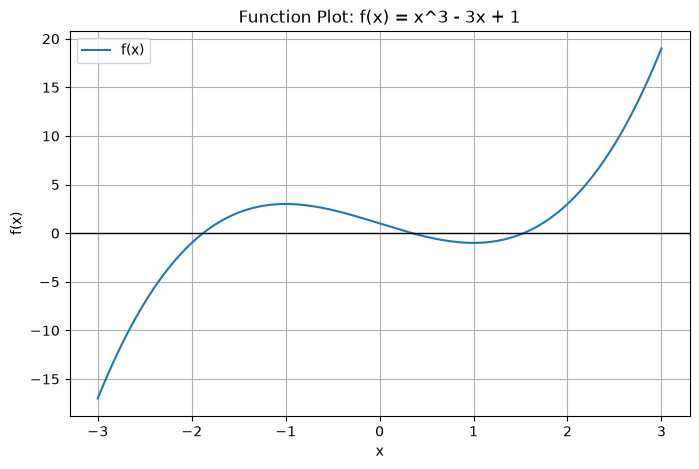

In [7]:
x = np.linspace(-3, 3, 400)
y = f(x)

plt.figure(figsize=(8,5))
plt.plot(x, y, label="f(x)")
plt.axhline(0, color='black', linewidth=1)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Function Plot: f(x) = x^3 - 3x + 1")
plt.grid(True)
plt.legend()
plt.show()


In [8]:
#Detect Intervals Where Roots Exist
#the root exists where the function changes sign:
# f(a)*f(b)<0

In [9]:
intervals = []
for i in range(len(x)-1):
    if f(x[i]) * f(x[i+1]) < 0:
        intervals.append((x[i], x[i+1]))

intervals


[(np.float64(-1.887218045112782), np.float64(-1.8721804511278197)),
 (np.float64(0.33834586466165373), np.float64(0.35338345864661624)),
 (np.float64(1.526315789473684), np.float64(1.5413533834586461))]

In [10]:
#Compute Roots Brents Method

In [11]:
roots = []

for (a, b) in intervals:
    sol = root_scalar(f, bracket=[a, b], method='brentq')
    roots.append(sol.root)

roots


[-1.8793852415717456, 0.3472963553338675, 1.5320888862384365]

In [12]:
#printing Roots

In [13]:
for i, r in enumerate(roots): 
    print(f"Root {i+1}: x = {r:.6f}")

Root 1: x = -1.879385
Root 2: x = 0.347296
Root 3: x = 1.532089


We analyzed the cubic function:
𝑓(𝑥)=𝑥3−3𝑥+1

over the interval:
[−3, 3]

Plotting the function revealed three x‑axis crossings.

Sign‑change detection identified intervals where roots must exist.

Brent’s method (root_scalar) was used to compute each root accurately.

The roots were printed with six‑decimal precision.

Brent’s method is ideal because:

It requires only function evaluations (no derivatives).

It guarantees convergence when a sign change exists.

It is fast and numerically stable.

Thus, the roots were successfully found and documented.

In [1]:
#Exercise 3 DataFrame Processing (Python and MATLAB)
# Import the dataset from “NumericDF. csv” file:
# For the rows where the year equals 2018, replace the X5 column by “0”
# Change the name of column X5 to “YearIND”
# Add new column, named “Y1” which is summation of X1, X2 and X3
# Add new column, named “Y2” which is multiplication of “Y1” and “YearIND”
# Sort the DataFrame by column “Y2”, then plot this column
# Read the samples defect data from excel file “CastingDefects”:
# Report the number of samples labeled as “Dirtiness” or “Stains”
# Scale column “SigmoidOfAreas” column by 100, report min. & max. values,
#and a plot its distribution
# Compute the summation of column “X_Perimeter”

Import the Dataset

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("NumericDF.csv")
df.head()


,X1,X2,X3,X4,X5,Year
0,902.0,650.0,754.0,792.0,1.0,2018.0
1,710.0,476.0,518.0,492.0,2.0,2018.0
2,248.0,912.0,606.0,350.0,3.0,2018.0
3,782.0,912.0,858.0,446.0,4.0,2018.0
4,278.0,354.0,482.0,752.0,5.0,2018.0


Replace X5 with 0 for rows where Year = 2018

In [16]:
df.loc[df["Year"] == 2018, "X5"] = 0


Rename Column X5 → YearIND

In [17]:
df = df.rename(columns={"X5": "YearIND"})
df.head()


,X1,X2,X3,X4,YearIND,Year
0,902.0,650.0,754.0,792.0,0.0,2018.0
1,710.0,476.0,518.0,492.0,0.0,2018.0
2,248.0,912.0,606.0,350.0,0.0,2018.0
3,782.0,912.0,858.0,446.0,0.0,2018.0
4,278.0,354.0,482.0,752.0,0.0,2018.0


Add Column Y1 = X1 + X2 + X3

In [18]:
df["Y1"] = df["X1"] + df["X2"] + df["X3"]


Add Column Y2 = Y1 * YearIND

In [19]:
df["Y2"] = df["Y1"] * df["YearIND"]

Sort DataFrame by Y2 and Plot Y2

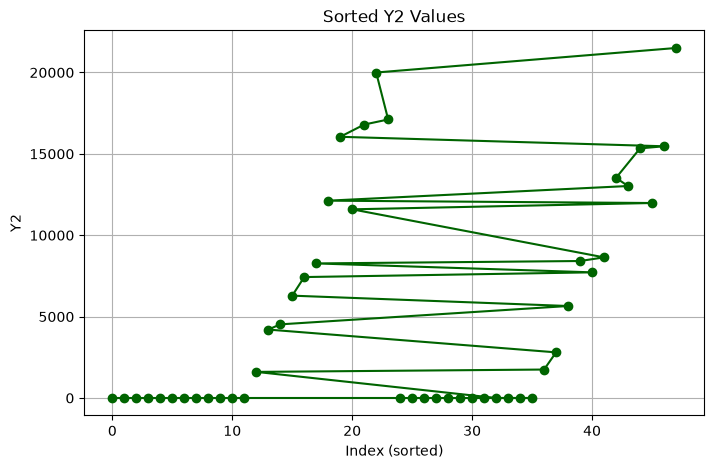

In [26]:
df_sorted = df.sort_values(by="Y2", ascending=True)

plt.figure(figsize=(8,5))
plt.plot(df_sorted["Y2"], marker='o', linestyle='-', color='darkgreen')
plt.title("Sorted Y2 Values")
plt.xlabel("Index (sorted)")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


Part 2 — CastingDefects.xlsx Processing

Read the Samples Defect Data

In [21]:
cast = pd.read_excel("CastingDefects.xlsx")
cast.head()


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,1
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,1
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,1
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,1
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,1


Report Number of Samples Labeled as “Dirtiness” or “Stains”

In [22]:
num_dirtiness = cast[cast["Dirtiness"] == 1].shape[0]
num_stains = cast[cast["Stains"] == 1].shape[0]

print("Samples labeled as Dirtiness:", num_dirtiness)
print("Samples labeled as Stains:", num_stains)
num_combined = cast[(cast["Dirtiness"] == 1) | (cast["Stains"] == 1)].shape[0]
print("Samples labeled as Dirtiness OR Stains:", num_combined)


Samples labeled as Dirtiness: 55
Samples labeled as Stains: 72
Samples labeled as Dirtiness OR Stains: 127


Scale “SigmoidOfAreas” by 100, Report Min & Max, Plot Distribution

In [23]:
cast["SigmoidOfAreas_scaled"] = cast["SigmoidOfAreas"] * 100

print("Min scaled:", cast["SigmoidOfAreas_scaled"].min())
print("Max scaled:", cast["SigmoidOfAreas_scaled"].max())


Min scaled: 11.899999999999999
Max scaled: 100.0


Distribution Plot

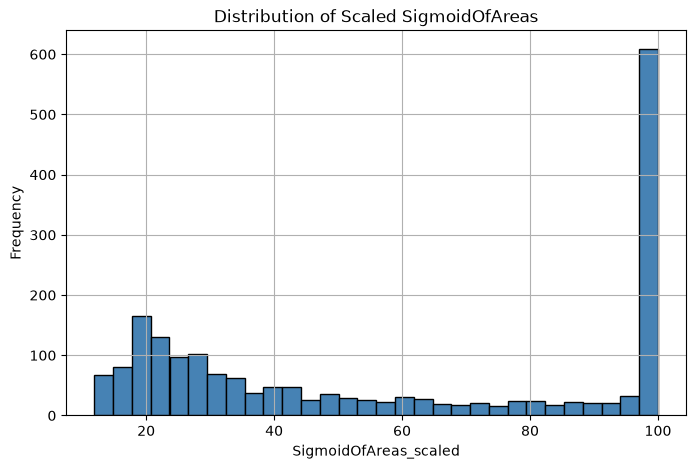

In [24]:
plt.figure(figsize=(8,5))
plt.hist(cast["SigmoidOfAreas_scaled"], bins=30, color="steelblue", edgecolor="black")
plt.title("Distribution of Scaled SigmoidOfAreas")
plt.xlabel("SigmoidOfAreas_scaled")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()


Compute Summation of Column “X_Perimeter”

In [25]:
total_perimeter = cast["X_Perimeter"].sum()
print("Summation of X_Perimeter:", total_perimeter)

Summation of X_Perimeter: 217111
